# Why DART looks better on an Optuna slice plot

*For readers who tune LightGBM with Optuna and keep `boosting_type` in the search space.*

In my work projects `optuna.visualization.plot_slice` often showed DART trials with a longer lower tail of log loss than `gbdt` and `goss` trials. In 2019 the CatBoost team declined a request to add DART ([catboost#1006](https://github.com/catboost/catboost/issues/1006)) and asked for an example where DART improves quality and tuning other parameters cannot match it. On 131 small datasets in [SmallDataBenchmarks](https://github.com/firefly1248/SmallDataBenchmarks) DART did not beat a second round of tuning of plain LightGBM. So where does the slice plot picture come from?

**The claim of this notebook.** LightGBM adds each new DART tree with weight `learning_rate / (1 + k)`, where `k` is the number of trees dropped in that round ([`src/boosting/dart.hpp`](https://github.com/microsoft/LightGBM/blob/v4.6.0/src/boosting/dart.hpp)). DART's step shrinks as training goes on. When the learning-rate range of a search starts at 0.1, `gbdt` and `goss` cannot take a small step per tree, but DART still gets one. A search can still shorten the total step of `gbdt` by using fewer trees; the sweeps below fix the number of trees, and the studies let the search pick 50 to 300. The noisier the data, the smaller the best step for `gbdt`.

The setting follows my work searches: 50-300 trees, no early stopping, selection on log loss.

1. The mechanism, measured on trained trees
2. Seven real datasets: log loss against learning rate
3. Slice plots with the learning rate on [0.1, 1] and on [0.001, 1], repeated over three seeds
4. The noise knob: synthetic data with growing label noise, three data and search seeds, and other explanations checked
5. What it means for a search space

Every expensive result is cached as CSV in `results/lightgbm/dart_slice_plot/`, so a rerun skips the sweeps and the studies. Outside a clone of the repository the notebook reads the published copy of that cache. Bank Marketing is downloaded from OpenML on every run (set `DART_DEMO_BANK_ARFF` to a local copy of the ARFF file to skip that); the other datasets are downloaded only when their cached sweep is missing.

In [1]:
import os
import time

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import sklearn
from lightgbm import LGBMClassifier
from sklearn.datasets import fetch_openml, make_classification
from sklearn.metrics import log_loss
from sklearn.model_selection import train_test_split

optuna.logging.set_verbosity(optuna.logging.WARNING)

SEED = 0
SEEDS = [0, 1, 2]   # replications: split, sampler and model seeds; SEED comes first
N_JOBS = -1                      # LightGBM threads per fit
N_TRIALS = 60   # per Optuna study
N_ROWS = 200_000
NOISE_LEVELS = [0.0, 0.1, 0.2, 0.3, 0.4]
LR_GRID = np.geomspace(0.005, 1.0, 15)
# OpenML ids of the other real datasets (binary targets; the rarer class is the positive one)
REAL = {"credit-g": 31, "diabetes": 37, "spambase": 44, "phoneme": 1489, "MagicTelescope": 1120, "adult": 1590}
MODES = ["gbdt", "goss", "dart"]
NARROW, WIDE = (0.1, 1.0), (0.001, 1.0)
RESULTS = "../../results/lightgbm/dart_slice_plot"
# the cache the full run wrote, pinned to the commit that added it
DATA_COMMIT = "501d9ee12c8f9f281aafff83c4de23a5f90fa6dd"
URL = f"https://raw.githubusercontent.com/firefly1248/demo-notebooks/{DATA_COMMIT}/results/lightgbm/dart_slice_plot/"
PUBLISHED = not os.path.isdir(RESULTS)   # outside a clone of the repository: read the published cache, compute nothing
if not PUBLISHED:
    os.makedirs(RESULTS, exist_ok=True)

print(f"lightgbm {lgb.__version__}, optuna {optuna.__version__}, scikit-learn {sklearn.__version__}")

lightgbm 4.6.0, optuna 4.7.0, scikit-learn 1.7.2


In [2]:
def make_model(mode, seed=SEED, **params):
    # GOSS is a sampling strategy of gbdt in LightGBM 4 and refuses bagging, so it gets no subsample.
    params = dict(params)
    if mode == "goss":
        params.pop("subsample", None)
        extra = {"boosting_type": "gbdt", "data_sample_strategy": "goss"}
    else:
        extra = {"boosting_type": mode, "subsample_freq": 1}
    if mode == "dart":
        extra["max_drop"] = -1   # the default caps a round at 50 dropped trees
    return LGBMClassifier(**params, **extra, random_state=seed, n_jobs=N_JOBS, verbose=-1)


def split(X, y, seed=SEED):
    # 60 % search-train, 20 % validation (what the search sees), 20 % test.
    X_fit, X_te, y_fit, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    X_tr, X_va, y_tr, y_va = train_test_split(X_fit, y_fit, test_size=0.25, stratify=y_fit, random_state=seed)
    return X_tr, X_va, X_te, y_tr, y_va, y_te


def valid_log_loss(model, X_va, y_va):
    return log_loss(y_va, model.predict_proba(X_va))


STUDIES = {}   # every cached TPE study of the joint kind, by name, for the allocation check


def cached(name, compute):
    path = os.path.join(RESULTS, f"{name}.csv")
    if PUBLISHED:
        df = pd.read_csv(URL + f"{name}.csv")
    elif os.path.exists(path):
        df = pd.read_csv(path)
    else:
        start = time.perf_counter()
        df = compute()
        df.to_csv(path, index=False)
        print(f"{name}: {time.perf_counter() - start:.0f} s")
    if "_trials_" in name:
        STUDIES[name] = df
    return df


def tagged(name, seed):
    # Seed SEED keeps the plain name, so the cache of a single-seed run stays valid.
    return name if seed == SEED else f"{name}_s{seed}"


def gap(refit, column):
    """DART minus gbdt in one column of a refit table; below zero, DART wins."""
    values = refit.set_index("boosting")[column]
    return values["dart"] - values["gbdt"]

## 1. DART's step shrinks as training goes on

LightGBM stores each tree's final weight as `shrinkage` in `booster_.dump_model()`. For `gbdt` every tree keeps the learning rate. For DART a new tree enters at `learning_rate / (1 + k)`, and each time it is dropped later its weight is multiplied by `k / (k + 1)`. With `skip_drop=0.5` half of the rounds drop nothing, so single trees still enter at the full step; the cumulative weight shows the total. Below: both modes with learning rate 0.5 and 300 trees, LightGBM's defaults `drop_rate=0.1` and `skip_drop=0.5`, with `max_drop` uncapped.

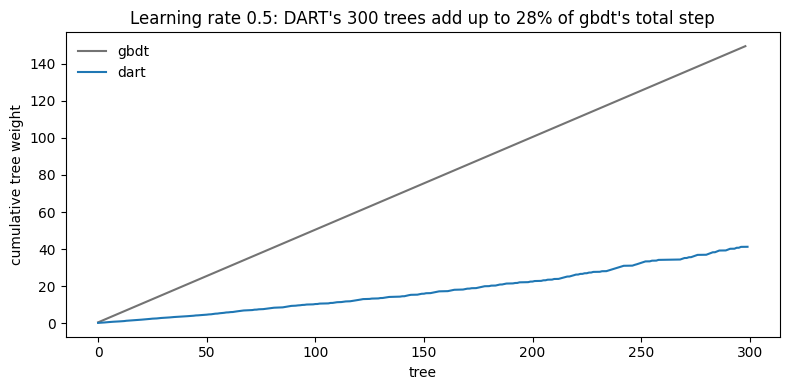

gbdt: sum of tree weights 149.5, median weight of the last 100 trees 0.500
dart: sum of tree weights 41.3, median weight of the last 100 trees 0.032


In [3]:
X_demo, y_demo = make_classification(20_000, 20, n_informative=6, n_redundant=4, flip_y=0.2, random_state=SEED)
weights = {}
for mode in ["gbdt", "dart"]:
    model = make_model(mode, learning_rate=0.5, n_estimators=300, num_leaves=64, subsample=0.8).fit(X_demo, y_demo)
    w = np.array([t["shrinkage"] for t in model.booster_.dump_model()["tree_info"]])
    weights[mode] = w[1:] if mode == "gbdt" else w   # gbdt's first tree holds the starting score (boost_from_average); DART's first tree holds it too but is dropped and rescaled like the others, so the sums cover 299 and 300 trees

share = weights["dart"].sum() / weights["gbdt"].sum()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.cumsum(weights["gbdt"]), color="0.45", label="gbdt")
ax.plot(np.cumsum(weights["dart"]), color="C0", label="dart")
ax.set_xlabel("tree")
ax.set_ylabel("cumulative tree weight")
ax.set_title(f"Learning rate 0.5: DART's 300 trees add up to {share:.0%} of gbdt's total step")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
for mode, w in weights.items():
    print(f"{mode}: sum of tree weights {w.sum():.1f}, median weight of the last 100 trees {np.median(w[-100:]):.3f}")

## 2. On real data the best step for DART sits higher than for gbdt

[Bank Marketing](https://www.openml.org/d/1461) (45,211 rows, 16 features, 11.7 % positive). Every mode with the same fixed parameters (300 trees, 64 leaves, `subsample` 0.8 where allowed, DART's `drop_rate` and `skip_drop` at their defaults and `max_drop` without a cap), only the learning rate moves. The gray band is the range [0.1, 1] that my work searches used. Six more OpenML datasets follow the same sweep for `gbdt` and DART; one split each, so a single dataset says little and the count over all seven is what to read.

In [4]:
def load_bank():
    local = os.environ.get("DART_DEMO_BANK_ARFF")   # optional local copy of OpenML 1461
    if local:
        from scipy.io import arff
        df = pd.DataFrame(arff.loadarff(local)[0])
        for col in df.select_dtypes(exclude="number").columns:
            df[col] = df[col].str.decode("utf-8")
    else:
        df = fetch_openml(data_id=1461, as_frame=True, parser="auto").frame
    y = (df.pop("Class").astype(str) == "2").astype(int).to_numpy()
    for col in df.select_dtypes(exclude="number").columns:
        df[col] = df[col].astype("category")
    return df, y

X_bank, y_bank = load_bank()
bank = split(X_bank, y_bank)
print(X_bank.shape, f"positive share {y_bank.mean():.3f}")

(45211, 16) positive share 0.117


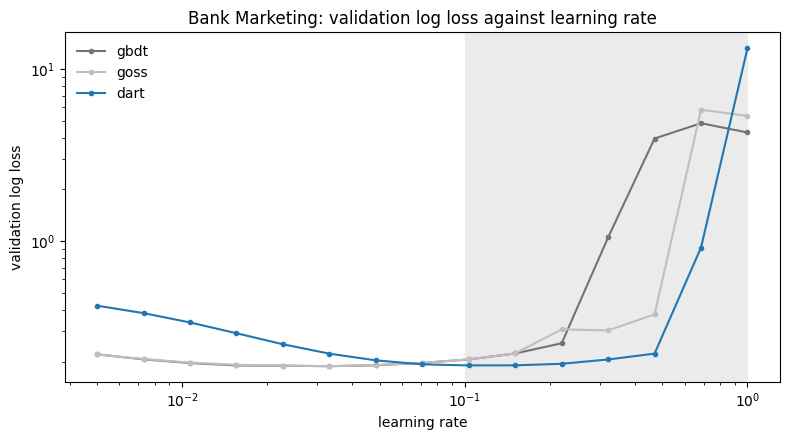

boosting  learning_rate  log_loss
    dart         0.1032    0.1904
    gbdt         0.0332    0.1884
    goss         0.0332    0.1883


In [5]:
FIXED = dict(n_estimators=300, num_leaves=64, min_child_samples=20, colsample_bytree=0.8, subsample=0.8)


def lr_sweep(data, modes, seed=SEED):
    X_tr, X_va, _, y_tr, y_va, _ = data
    rows = []
    for mode in modes:
        for lr in LR_GRID:
            model = make_model(mode, seed, learning_rate=lr, **FIXED).fit(X_tr, y_tr)
            rows.append({"boosting": mode, "learning_rate": lr, "log_loss": valid_log_loss(model, X_va, y_va)})
    return pd.DataFrame(rows)


def plot_sweep(sweep, title, ax):
    ax.axvspan(*NARROW, color="0.92", zorder=0)
    for mode, color in zip(MODES, ["0.45", "0.75", "C0"]):
        part = sweep[sweep.boosting == mode]
        if len(part):
            ax.plot(part.learning_rate, part.log_loss, marker="o", ms=3, color=color, label=mode)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("learning rate")
    ax.set_ylabel("validation log loss")
    ax.set_title(title)
    ax.legend(frameon=False)


sweep_bank = cached("bank_lr_sweep", lambda: lr_sweep(bank, MODES))
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_sweep(sweep_bank, "Bank Marketing: validation log loss against learning rate", ax)
fig.tight_layout()
plt.show()
print(sweep_bank.loc[sweep_bank.groupby("boosting").log_loss.idxmin()].round(4).to_string(index=False))

       dataset  rows  positive  gbdt_best_lr  dart_best_lr  gbdt_best_loss  dart_best_loss
          bank 45211    0.1170        0.0332        0.1032          0.1884          0.1904
      credit-g  1000    0.3000        0.0107        0.0484          0.5046          0.5045
      diabetes   768    0.3490        0.0073        0.0332          0.4986          0.5025
      spambase  4601    0.3940        0.0227        0.1032          0.1193          0.1223
       phoneme  5404    0.2935        0.0332        0.1032          0.2299          0.2313
MagicTelescope 19020    0.3516        0.0332        0.1032          0.2796          0.2816
         adult 48842    0.2393        0.0332        0.1032          0.2791          0.2806
DART's best step is higher than gbdt's on 7 of 7 datasets; gbdt's best step is below 0.1 on 7, DART's on 2; DART's best log loss is lower on 1.


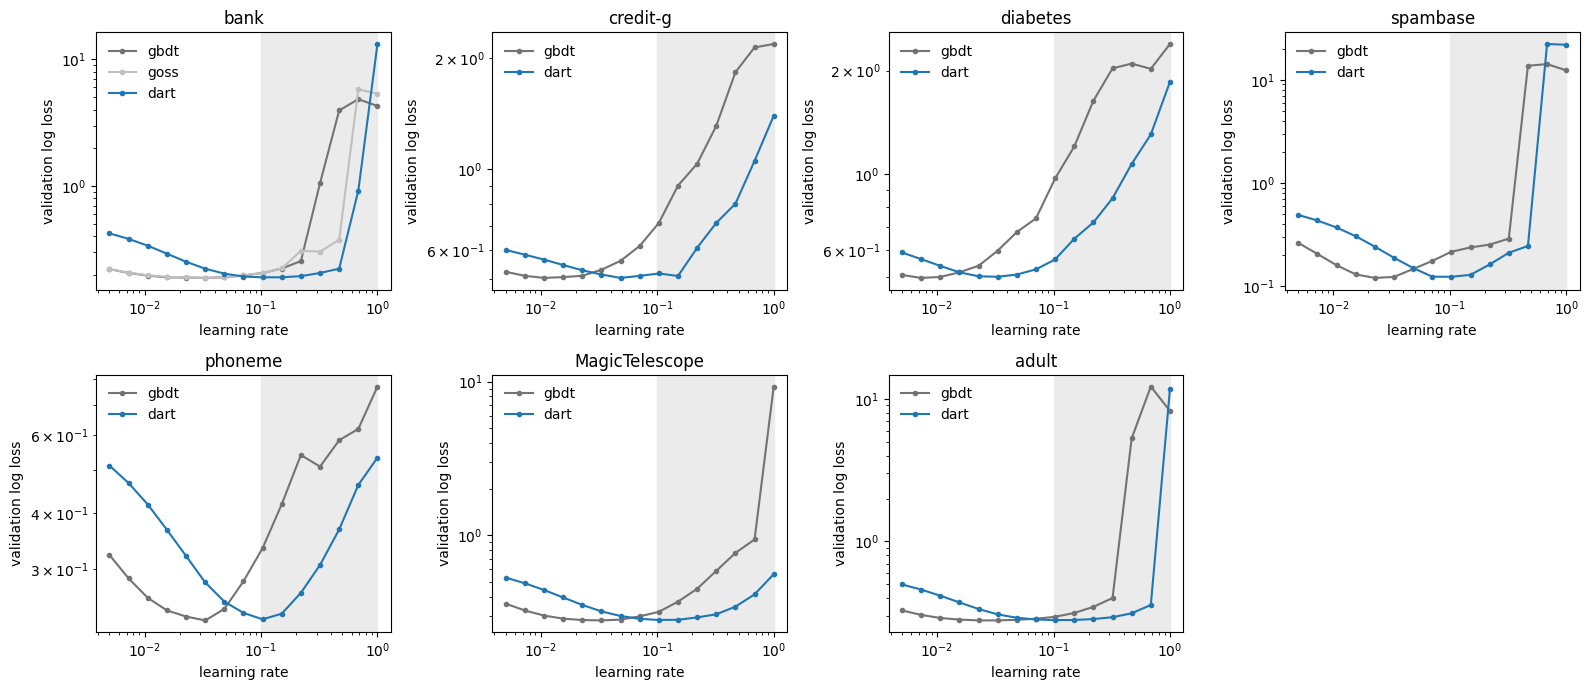

In [6]:
def load_openml(data_id):
    X, y = fetch_openml(data_id=data_id, as_frame=True, parser="auto", return_X_y=True)
    X.columns = [f"x{i}" for i in range(X.shape[1])]   # LightGBM rejects some characters in feature names
    for col in X.select_dtypes(exclude="number").columns:
        X[col] = X[col].astype("category")
    return X, (y == y.value_counts().idxmin()).astype(int).to_numpy()


def real_sweep(data_id):
    X, y = load_openml(data_id)
    return lr_sweep(split(X, y), ["gbdt", "dart"]).assign(rows=len(y), positive=y.mean())


real_sweeps = {"bank": sweep_bank.assign(rows=len(y_bank), positive=y_bank.mean())}
for name, data_id in REAL.items():
    real_sweeps[name] = cached(f"real_{name}_lr_sweep", lambda: real_sweep(data_id))

rows = []
for name, sweep in real_sweeps.items():
    sweep = sweep[sweep.boosting.isin(["gbdt", "dart"])]
    best = sweep.loc[sweep.groupby("boosting").log_loss.idxmin()].set_index("boosting")
    rows.append({"dataset": name, "rows": sweep.rows.iloc[0], "positive": sweep.positive.iloc[0],
                 "gbdt_best_lr": best.learning_rate["gbdt"], "dart_best_lr": best.learning_rate["dart"],
                 "gbdt_best_loss": best.log_loss["gbdt"], "dart_best_loss": best.log_loss["dart"]})
real_table = pd.DataFrame(rows)
print(real_table.round(4).to_string(index=False))
print(f"DART's best step is higher than gbdt's on {(real_table.dart_best_lr > real_table.gbdt_best_lr).sum()} of "
      f"{len(real_table)} datasets; gbdt's best step is below 0.1 on {(real_table.gbdt_best_lr < NARROW[0]).sum()}, "
      f"DART's on {(real_table.dart_best_lr < NARROW[0]).sum()}; "
      f"DART's best log loss is lower on {(real_table.dart_best_loss < real_table.gbdt_best_loss).sum()}.")

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, (name, sweep) in zip(axes.flat, real_sweeps.items()):
    plot_sweep(sweep, name, ax)
for ax in axes.flat[len(real_sweeps):]:
    ax.set_visible(False)
fig.tight_layout()
plt.show()

## 3. Slice plots: the learning-rate range changes who looks better

One Optuna TPE study per range, as in a typical setup: `boosting` is a categorical parameter, 50-300 trees, no early stopping, the objective is validation log loss. DART adds `drop_rate` (log-uniform on [0.01, 0.5]) and `skip_drop` (uniform on [0, 0.5]). The best trial of each mode is refit on search-train plus validation rows and scored on the test rows.

The study with seed 0 is drawn below. The cell after it repeats both studies on Bank Marketing with seeds 0, 1 and 2 (each seed changes the split, the TPE sampler and the model seed) and compares the refit test log loss of the best DART and best `gbdt` trial: one TPE run is a single draw, and the three modes get unequal shares of 60 trials. The search space is the same for all modes except that DART tunes two extra parameters (`drop_rate`, `skip_drop`) and GOSS keeps LightGBM's `top_rate` and `other_rate`.

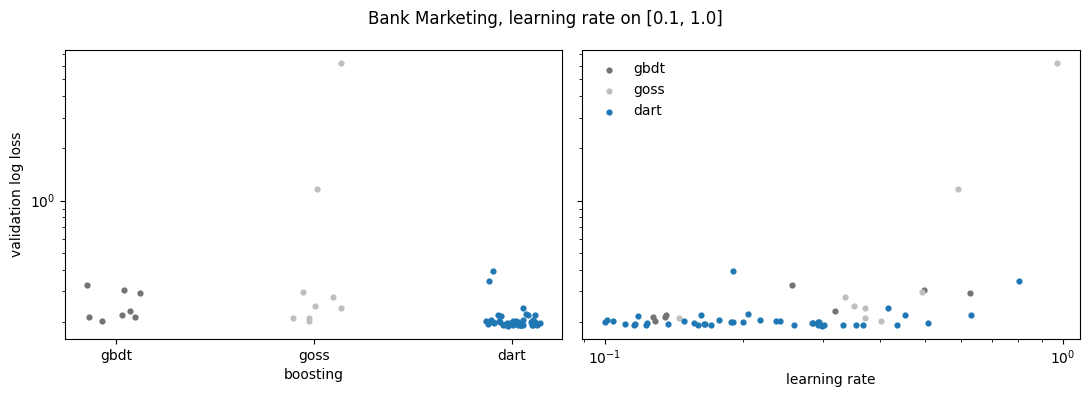

boosting  trials  best_valid  p10_valid  median_valid  test_log_loss  best_learning_rate
    dart      43      0.1894     0.1917        0.1977         0.1934              0.2977
    gbdt       8      0.2033     0.2097        0.2245         0.2039              0.1289
    goss       9      0.2019     0.2087        0.2473         0.2039              0.4006


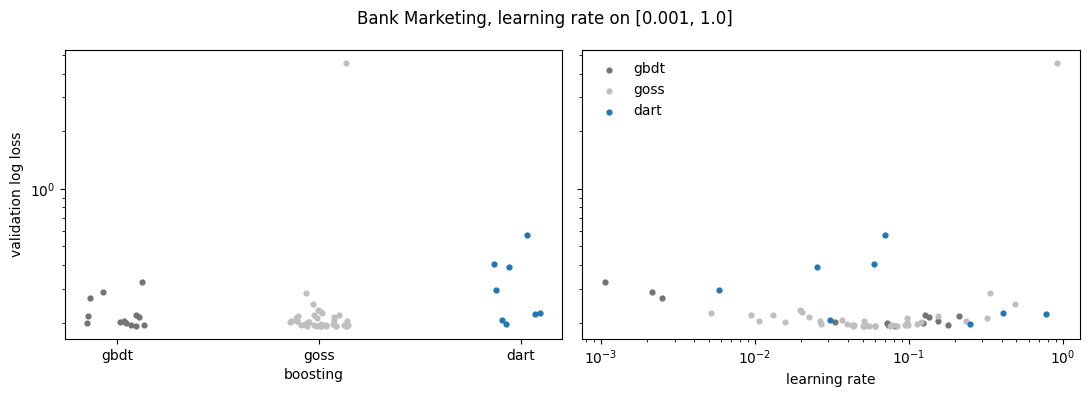

boosting  trials  best_valid  p10_valid  median_valid  test_log_loss  best_learning_rate
    dart       8      0.1961     0.2028        0.2597         0.1972              0.2497
    gbdt      13      0.1918     0.1939        0.2037         0.1934              0.0813
    goss      39      0.1919     0.1922        0.2016         0.1938              0.0841


In [7]:
def suggest(trial, lr_range, mode=None):
    mode = mode or trial.suggest_categorical("boosting", MODES)
    params = {
        "learning_rate":     trial.suggest_float("learning_rate", *lr_range, log=True),
        "n_estimators":      trial.suggest_int("n_estimators", 50, 300),
        "num_leaves":        trial.suggest_int("num_leaves", 8, 256),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
        "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.4, 1.0),
        "reg_lambda":        trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
    }
    if mode != "goss":
        params["subsample"] = trial.suggest_float("subsample", 0.4, 1.0)
    if mode == "dart":
        params["drop_rate"] = trial.suggest_float("drop_rate", 0.01, 0.5, log=True)
        params["skip_drop"] = trial.suggest_float("skip_drop", 0.0, 0.5)
    return mode, params


def run_study(data, lr_range, seed=SEED, mode=None, n_trials=N_TRIALS):
    X_tr, X_va, _, y_tr, y_va, _ = data

    def objective(trial):
        chosen, params = suggest(trial, lr_range, mode)
        return valid_log_loss(make_model(chosen, seed, **params).fit(X_tr, y_tr), X_va, y_va)

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=n_trials)
    return study


def trials_frame(study):
    df = study.trials_dataframe(attrs=("number", "value", "params"))
    df.columns = [c.replace("params_", "") for c in df.columns]
    return df.rename(columns={"value": "log_loss"})


def best_params(part):
    best = part.loc[part.log_loss.idxmin()]
    params = {k: best[k] for k in ["learning_rate", "n_estimators", "num_leaves", "min_child_samples",
                                   "colsample_bytree", "reg_lambda", "subsample", "drop_rate", "skip_drop"]
              if k in best and pd.notna(best[k])}
    for k in ["n_estimators", "num_leaves", "min_child_samples"]:
        params[k] = int(params[k])
    return best, params


def refit_best(trials, data, seed=SEED):
    X_tr, X_va, X_te, y_tr, y_va, y_te = data
    X_fit, y_fit = pd.concat([X_tr, X_va]), np.r_[y_tr, y_va]
    rows = []
    for mode, part in trials.groupby("boosting"):
        best, params = best_params(part)
        model = make_model(mode, seed, **params).fit(X_fit, y_fit)
        rows.append({"boosting": mode, "trials": len(part), "best_valid": best.log_loss,
                     "p10_valid": part.log_loss.quantile(0.1), "median_valid": part.log_loss.median(),
                     "test_log_loss": log_loss(y_te, model.predict_proba(X_te)),
                     "best_learning_rate": params["learning_rate"]})
    return pd.DataFrame(rows)


def plot_slices(trials, title):
    # The two panels of optuna.visualization.matplotlib.plot_slice that matter here, drawn from the cached trials.
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for i, mode in enumerate(MODES):
        part = trials[trials.boosting == mode]
        jitter = np.random.default_rng(i).uniform(-0.15, 0.15, len(part))
        axes[0].scatter(i + jitter, part.log_loss, s=12, color=["0.45", "0.75", "C0"][i])
        axes[1].scatter(part.learning_rate, part.log_loss, s=12, color=["0.45", "0.75", "C0"][i], label=mode)
    axes[0].set_xticks(range(len(MODES)), MODES)
    axes[0].set_xlabel("boosting")
    axes[0].set_ylabel("validation log loss")
    axes[1].set_xscale("log")
    axes[1].set_xlabel("learning rate")
    axes[1].legend(frameon=False)
    for ax in axes:
        ax.set_yscale("log")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


bank_trials = {}
for name, lr_range in [("narrow", NARROW), ("wide", WIDE)]:
    bank_trials[name] = cached(f"bank_trials_{name}", lambda r=lr_range: trials_frame(run_study(bank, r)))
    plot_slices(bank_trials[name], f"Bank Marketing, learning rate on [{lr_range[0]}, {lr_range[1]}]")
    print(cached(f"bank_refit_{name}", lambda n=name: refit_best(bank_trials[n], bank)).round(4).to_string(index=False))

In [8]:
rows = []
for seed in SEEDS:
    data = bank if seed == SEED else split(X_bank, y_bank, seed)
    for name, lr_range in [("narrow", NARROW), ("wide", WIDE)]:
        trials = cached(tagged(f"bank_trials_{name}", seed), lambda: trials_frame(run_study(data, lr_range, seed)))
        refit = cached(tagged(f"bank_refit_{name}", seed), lambda: refit_best(trials, data, seed))
        rows.append({"seed": seed, "range": name, "dart_trials": int(refit.set_index("boosting").trials["dart"]),
                     "gap_valid": gap(refit, "best_valid"), "gap_test": gap(refit, "test_log_loss")})
bank_gaps = pd.DataFrame(rows)
print("Bank Marketing, best DART minus best gbdt (below zero: DART wins)")
print(bank_gaps.round(4).to_string(index=False))
print(bank_gaps.groupby("range")[["gap_valid", "gap_test"]].agg(["mean", "std"]).round(4).to_string())

Bank Marketing, best DART minus best gbdt (below zero: DART wins)
 seed  range  dart_trials  gap_valid  gap_test
    0 narrow           43    -0.0139   -0.0106
    0   wide            8     0.0043    0.0038
    1 narrow           42    -0.0073   -0.0075
    1   wide            7     0.0117    0.0076
    2 narrow           25    -0.0081   -0.0058
    2   wide            8     0.0133    0.0107
       gap_valid         gap_test        
            mean     std     mean     std
range                                    
narrow   -0.0098  0.0036  -0.0079  0.0024
wide      0.0097  0.0048   0.0074  0.0035


For readability the slice plots above are drawn from the cached trials: the left panel is the `boosting` panel of `plot_slice`, the right one the `learning_rate` panel, colored by mode. To see Optuna's own figure, run `optuna.visualization.plot_slice(run_study(bank, NARROW), params=["boosting", "learning_rate"])`.

## 4. The noise knob

If the claim holds, label noise should move `gbdt`'s best step down, below the floor of the narrow range, and DART's advantage on that range should grow with it. `make_classification` with `flip_y=f` gives a random class to a share `f` of the rows, so about `f / 2` of the labels are wrong. 200,000 rows, 20 features (6 informative, 4 redundant), the same sweep and the same two studies for each noise level, repeated with seeds 0, 1 and 2 (a new draw of the data, the split, the sampler and the models).

Predictions, written before the run:

1. `gbdt`'s best learning rate in the sweep falls as noise rises.
2. On [0.1, 1] the gap "best DART minus best gbdt" in validation log loss falls as noise rises and turns negative.
3. On [0.001, 1] DART's lead at the highest noise level is less than half of its lead on [0.1, 1].

Predictions 1 and 2 compare the highest noise level with zero noise, prediction 3 looks at the highest noise level only (DART behind on the wide range counts as less than half of a lead), and a prediction counts as held only if it holds in every seed. The claim is about how the slice plot looks, and a slice plot shows validation values, so the checks use the validation gaps. The same gaps on the test rows, after refitting each mode's best trial, are printed next to them to show whether the picture is real. Predictions 2 and 3 are also checked on the sweeps, where every other parameter is fixed and no sampler allocates trials (the narrow range keeps the grid points from 0.1 up). That version was added after the study version of prediction 2 failed, so it is a follow-up, not a prediction written beforehand.

A fourth prediction was written after the runs had started and before their sweeps were read. Section 1 gives DART's share of `gbdt`'s total step, so DART's best learning rate should exceed `gbdt`'s by about the inverse of that share, within one grid step.

4. The median of "DART's best learning rate over `gbdt`'s" across all the sweeps of sections 2 and 4 is within one grid step of 1 / share. The share depends on the drop pattern and not on the data, so this is a check of magnitude, not of a trend.

In [9]:
def synthetic(noise, seed=SEED):
    X, y = make_classification(N_ROWS, 20, n_informative=6, n_redundant=4, flip_y=noise, random_state=seed)
    return pd.DataFrame(X, columns=[f"x{i}" for i in range(X.shape[1])]), y


rows = []
for seed in SEEDS:
    for noise in NOISE_LEVELS:
        data = split(*synthetic(noise, seed), seed)
        tag = f"noise{int(noise * 100):02d}"
        sweep = cached(tagged(f"{tag}_lr_sweep", seed), lambda: lr_sweep(data, ["gbdt", "dart"], seed))
        best_lr = sweep.loc[sweep.groupby("boosting").log_loss.idxmin()].set_index("boosting").learning_rate
        row = {"seed": seed, "noise": noise, "gbdt_best_lr": best_lr["gbdt"], "dart_best_lr": best_lr["dart"]}
        by_lr = sweep.pivot(index="learning_rate", columns="boosting", values="log_loss")
        high = by_lr[by_lr.index >= NARROW[0]]
        row["narrow_gap_sweep"] = high.dart.min() - high.gbdt.min()
        row["wide_gap_sweep"] = by_lr.dart.min() - by_lr.gbdt.min()
        for name, lr_range in [("narrow", NARROW), ("wide", WIDE)]:
            trials = cached(tagged(f"{tag}_trials_{name}", seed), lambda: trials_frame(run_study(data, lr_range, seed)))
            refit = cached(tagged(f"{tag}_refit_{name}", seed), lambda: refit_best(trials, data, seed))
            row[f"{name}_gap_valid"] = gap(refit, "best_valid")
            row[f"{name}_gap_test"] = gap(refit, "test_log_loss")
            row[f"{name}_dart_trials"] = int(refit.set_index("boosting").trials["dart"])
            row[f"{name}_gbdt_trials"] = int(refit.set_index("boosting").trials["gbdt"])
        rows.append(row)

noise_table = pd.DataFrame(rows)
print(noise_table.round(4).to_string(index=False))
print("\nmean and sd over seeds")
print(noise_table.groupby("noise")[["gbdt_best_lr", "dart_best_lr", "narrow_gap_valid", "wide_gap_valid",
                                    "narrow_gap_test", "wide_gap_test", "narrow_gap_sweep", "wide_gap_sweep"]].agg(["mean", "std"]).round(4).to_string())

 seed  noise  gbdt_best_lr  dart_best_lr  narrow_gap_sweep  wide_gap_sweep  narrow_gap_valid  narrow_gap_test  narrow_dart_trials  narrow_gbdt_trials  wide_gap_valid  wide_gap_test  wide_dart_trials  wide_gbdt_trials
    0    0.0        0.1507        0.3213            0.0001          0.0001            0.0026           0.0050                   7                  32          0.0061         0.0064                 7                39
    0    0.1        0.0484        0.1507           -0.0054         -0.0027           -0.0039          -0.0028                  42                   9          0.0010         0.0015                10                12
    0    0.2        0.0332        0.1032           -0.0072         -0.0011           -0.0056          -0.0054                  41                  10         -0.0090        -0.0083                40                 7
    0    0.3        0.0332        0.1032           -0.0076         -0.0007           -0.0024          -0.0010                  43   

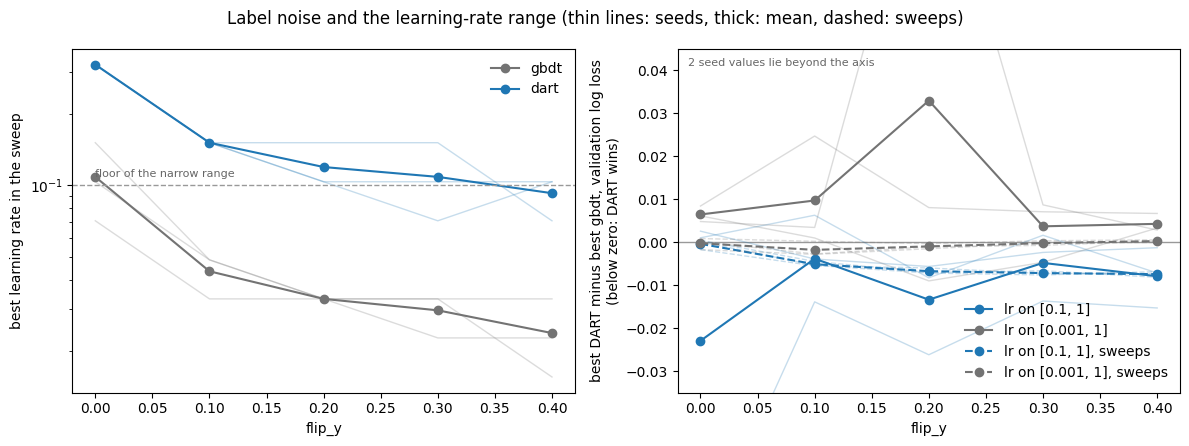

Gaps on the validation rows:
  held    1. gbdt's best lr is lower at the highest noise than at zero noise  (3 of 3 seeds)
  FAILED  2. on [0.1, 1] DART's gap is lower at the highest noise than at zero noise, and negative  (2 of 3 seeds)
  held    3. on [0.001, 1] DART's lead at the highest noise is under half of its lead on [0.1, 1] (DART behind counts)  (3 of 3 seeds)
Gaps on the test rows after the refit:
  FAILED  2. on [0.1, 1] DART's gap is lower at the highest noise than at zero noise, and negative  (2 of 3 seeds)
  held    3. on [0.001, 1] DART's lead at the highest noise is under half of its lead on [0.1, 1] (DART behind counts)  (3 of 3 seeds)
Gaps on the sweeps at fixed parameters:
  held    2. on [0.1, 1] DART's gap is lower at the highest noise than at zero noise, and negative  (3 of 3 seeds)
  held    3. on [0.001, 1] DART's lead at the highest noise is under half of its lead on [0.1, 1] (DART behind counts)  (3 of 3 seeds)


In [10]:
def draw(ax, column, color, label, ls="-"):
    for _, part in noise_table.groupby("seed"):
        ax.plot(part.noise, part[column], color=color, alpha=0.25, lw=1, ls=ls)
    ax.plot(noise_table.groupby("noise")[column].mean(), marker="o", color=color, label=label, ls=ls)


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
draw(axes[0], "gbdt_best_lr", "0.45", "gbdt")
draw(axes[0], "dart_best_lr", "C0", "dart")
axes[0].axhline(NARROW[0], color="0.6", ls="--", lw=1)
axes[0].text(noise_table.noise.min(), NARROW[0] * 1.08, "floor of the narrow range", fontsize=8, color="0.4")
axes[0].set_yscale("log")
axes[0].set_xlabel("flip_y")
axes[0].set_ylabel("best learning rate in the sweep")
axes[0].legend(frameon=False)
axes[1].axhline(0, color="0.6", lw=1)
draw(axes[1], "narrow_gap_valid", "C0", "lr on [0.1, 1]")
draw(axes[1], "wide_gap_valid", "0.45", "lr on [0.001, 1]")
draw(axes[1], "narrow_gap_sweep", "C0", "lr on [0.1, 1], sweeps", ls="--")
draw(axes[1], "wide_gap_sweep", "0.45", "lr on [0.001, 1], sweeps", ls="--")
axes[1].set_xlabel("flip_y")
axes[1].set_ylabel("best DART minus best gbdt, validation log loss\n(below zero: DART wins)")
limits = (-0.035, 0.045)
axes[1].set_ylim(*limits)
gap_columns = ["narrow_gap_valid", "wide_gap_valid"]
beyond = int(((noise_table[gap_columns] < limits[0]) | (noise_table[gap_columns] > limits[1])).to_numpy().sum())
axes[1].text(0.02, 0.95, f"{beyond} seed values lie beyond the axis", transform=axes[1].transAxes, fontsize=8, color="0.4")
axes[1].legend(frameon=False, loc="lower right")
fig.suptitle("Label noise and the learning-rate range (thin lines: seeds, thick: mean, dashed: sweeps)")
fig.tight_layout()
plt.show()

PREDICTIONS = {
    1: "gbdt's best lr is lower at the highest noise than at zero noise",
    2: "on [0.1, 1] DART's gap is lower at the highest noise than at zero noise, and negative",
    3: "on [0.001, 1] DART's lead at the highest noise is under half of its lead on [0.1, 1] (DART behind counts)",
}


def held_by_prediction(part, where):
    first, last = part.iloc[0], part.iloc[-1]   # lowest and highest noise
    narrow, wide = f"narrow_gap_{where}", f"wide_gap_{where}"
    lead_narrow, lead_wide = -last[narrow], -last[wide]
    return {1: last.gbdt_best_lr < first.gbdt_best_lr,
            2: last[narrow] < first[narrow] and last[narrow] < 0,
            3: lead_narrow > 0 and lead_wide < lead_narrow / 2}


for where, label in [("valid", "validation rows"), ("test", "test rows after the refit"), ("sweep", "sweeps at fixed parameters")]:
    held = pd.DataFrame({seed: held_by_prediction(part, where) for seed, part in noise_table.groupby("seed")})
    print(f"Gaps on the {label}:")
    for i, text in PREDICTIONS.items():
        if i > 1 or where == "valid":
            print(f"  {'held  ' if held.loc[i].all() else 'FAILED'}  {i}. {text}  ({held.loc[i].sum()} of {held.shape[1]} seeds)")

In [11]:
ratios = pd.concat([real_table.dart_best_lr / real_table.gbdt_best_lr, noise_table.dart_best_lr / noise_table.gbdt_best_lr])
expected, grid_step = 1 / share, LR_GRID[1] / LR_GRID[0]
within = (np.abs(np.log(ratios / expected)) <= np.log(grid_step)).sum()
held4 = abs(np.log(ratios.median() / expected)) <= np.log(grid_step)
print(f"{'held  ' if held4 else 'FAILED'}  4. DART's best lr over gbdt's, median of {len(ratios)} sweeps: {ratios.median():.2f} "
      f"(quartiles {ratios.quantile(0.25):.2f} to {ratios.quantile(0.75):.2f}); 1 / share = {expected:.2f}; one grid step = {grid_step:.2f}; "
      f"{within} of {len(ratios)} sweeps within one grid step")

held    4. DART's best lr over gbdt's, median of 22 sweeps: 3.11 (quartiles 3.11 to 4.54); 1 / share = 3.62; one grid step = 1.46; 21 of 22 sweeps within one grid step


### Other explanations

The learning-rate step is one explanation of the slice plot, not necessarily the only one. Below are four checks on the cached results: three other explanations and one control that removes the confound of the first.

1. **Trial allocation.** The categorical `boosting` parameter lets TPE send most trials to whichever mode looks best. TPE also samples the learning rate from one density shared by all modes, so a mode with few trials gets them where the majority mode's good trials are, which can starve it. Below, over all cached studies: the gap "best DART minus best gbdt" as it is, with both modes cut to the same number of trials (random subsets, so this equalises the count and not where TPE put the trials), against the best of gbdt and goss, and a cross-tabulation of the verdict with the mode that got the most trials.
2. **One study per mode (a control for 1).** The sampler cannot move trials between modes, or share a learning-rate density between them, if each mode has its own study. Bank Marketing only, three seeds, a third of the trials per mode (twenty, ten of them TPE's random start), the same search space. The budgets differ from the joint studies in both directions, so each mode's search is short and the result is rough.
3. **Luck of the draw.** DART drops trees at random, so its best trial could be luckier than gbdt's best trial. The best parameters of each mode on Bank Marketing, trained with five seeds on the search-train rows and scored on the validation rows: the winner's curse is the seed-0 value (the one the search saw) against the mean of the other four.
4. **The dropout itself.** If the step were the whole story, dropping trees would help at high learning rates and hurt at low ones. Below, the rank correlation of a DART trial's log loss (rank within its study) with `skip_drop` and `drop_rate`, by learning-rate band; a positive value means a larger parameter goes with a worse trial. The lowest band holds trials of the wide-range studies only, where DART often got few trials, and a step effect and a regularisation effect would both produce this sign pattern, so the table cannot tell them apart.

In [12]:
rng = np.random.default_rng(SEED)


def best_of(values, k, draws=1000):
    return np.mean([rng.choice(values, k, replace=False).min() for _ in range(draws)])


rows = []
for name, t in STUDIES.items():
    by_mode = {m: t.log_loss[t.boosting == m].to_numpy() for m in MODES}
    k = min(len(by_mode["dart"]), len(by_mode["gbdt"]))
    rows.append({"range": "narrow" if "narrow" in name else "wide",
                 "dart_trials": len(by_mode["dart"]), "gbdt_trials": len(by_mode["gbdt"]),
                 "dart_most_trials": len(by_mode["dart"]) == max(len(v) for v in by_mode.values()),
                 "gap": by_mode["dart"].min() - by_mode["gbdt"].min(),
                 "gap_equal_trials": best_of(by_mode["dart"], k) - best_of(by_mode["gbdt"], k),
                 "gap_vs_gbdt_goss": by_mode["dart"].min() - min(by_mode["gbdt"].min(), by_mode["goss"].min())})
allocation = pd.DataFrame(rows)
print(allocation.groupby("range").agg(
    studies=("gap", "size"), dart_trials=("dart_trials", "mean"), gbdt_trials=("gbdt_trials", "mean"),
    gap=("gap", "mean"), gap_equal_trials=("gap_equal_trials", "mean"), gap_vs_gbdt_goss=("gap_vs_gbdt_goss", "mean"),
    dart_wins=("gap", lambda g: (g < 0).sum()), dart_wins_equal_trials=("gap_equal_trials", lambda g: (g < 0).sum()),
).round(4).to_string())
print()
print(pd.crosstab(allocation.dart_most_trials.rename("DART got the most trials"),
                  (allocation.gap < 0).rename("DART's best beat gbdt's")).to_string())

        studies  dart_trials  gbdt_trials     gap  gap_equal_trials  gap_vs_gbdt_goss  dart_wins  dart_wins_equal_trials
range                                                                                                                   
narrow       18      34.1111      12.9444 -0.0104           -0.0098           -0.0050         14                      14
wide         18      12.0000      23.6667  0.0112            0.0105            0.0122          2                       2

DART's best beat gbdt's   False  True 
DART got the most trials              
False                        20      1
True                          0     15


In [13]:
rows = []
for seed in SEEDS:
    data = bank if seed == SEED else split(X_bank, y_bank, seed)
    for name, lr_range in [("narrow", NARROW), ("wide", WIDE)]:
        trials = pd.concat([cached(tagged(f"bank_{mode}_only_{name}", seed), lambda: trials_frame(
            run_study(data, lr_range, seed, mode, N_TRIALS // 3)).assign(boosting=mode)) for mode in ["gbdt", "dart"]])
        refit = cached(tagged(f"bank_one_study_per_mode_refit_{name}", seed), lambda: refit_best(trials, data, seed))
        rows.append({"seed": seed, "range": name, "gap_valid": gap(refit, "best_valid"), "gap_test": gap(refit, "test_log_loss")})
one_study_per_mode = pd.DataFrame(rows)
print("Bank Marketing, one study per mode, best DART minus best gbdt (below zero: DART wins)")
print(one_study_per_mode.round(4).to_string(index=False))
print(one_study_per_mode.groupby("range")[["gap_valid", "gap_test"]].agg(["mean", "std"]).round(4).to_string())

Bank Marketing, one study per mode, best DART minus best gbdt (below zero: DART wins)
 seed  range  gap_valid  gap_test
    0 narrow     0.0037    0.0008
    0   wide     0.0086    0.0064
    1 narrow     0.0012   -0.0008
    1   wide     0.0062    0.0033
    2 narrow    -0.0074   -0.0030
    2   wide    -0.0013   -0.0021
       gap_valid         gap_test        
            mean     std     mean     std
range                                    
narrow   -0.0008  0.0058  -0.0010  0.0019
wide      0.0045  0.0051   0.0025  0.0043


In [14]:
def seed_variance(trials, data, n_seeds=5):
    X_tr, X_va, _, y_tr, y_va, _ = data
    rows = []
    for mode in ["gbdt", "dart"]:
        _, params = best_params(trials[trials.boosting == mode])
        for seed in range(n_seeds):
            rows.append({"boosting": mode, "seed": seed,
                         "log_loss": valid_log_loss(make_model(mode, seed, **params).fit(X_tr, y_tr), X_va, y_va)})
    return pd.DataFrame(rows)


seeds_bank = cached("bank_seed_variance", lambda: seed_variance(bank_trials["narrow"], bank))
by_mode = seeds_bank.groupby("boosting").log_loss
luck = pd.DataFrame({"seed_0 (seen by the search)": by_mode.first(), "mean of seeds 1-4": by_mode.apply(lambda v: v.iloc[1:].mean()),
                     "sd over the 5 seeds": by_mode.std()})
luck["winner's curse"] = luck["mean of seeds 1-4"] - luck["seed_0 (seen by the search)"]
print(luck.round(4).to_string())

          seed_0 (seen by the search)  mean of seeds 1-4  sd over the 5 seeds  winner's curse
boosting                                                                                     
dart                           0.1894             0.1910               0.0014          0.0016
gbdt                           0.2033             0.2025               0.0013         -0.0008


In [15]:
dart_trials = pd.concat([t[t.boosting == "dart"].assign(study=name) for name, t in STUDIES.items()])
dart_trials["loss_rank"] = dart_trials.groupby("study").log_loss.rank(pct=True)
dart_trials["learning rate"] = pd.cut(dart_trials.learning_rate, [0, 0.1, 0.3, 1.01], right=False, labels=["< 0.1", "0.1 to 0.3", ">= 0.3"])
print(dart_trials.groupby("learning rate", observed=True).apply(lambda g: pd.Series({
    "trials": len(g), "skip_drop": g.skip_drop.corr(g.loss_rank, method="spearman"),
    "drop_rate": g.drop_rate.corr(g.loss_rank, method="spearman")}), include_groups=False).round(2).to_string())

               trials  skip_drop  drop_rate
learning rate                              
< 0.1           123.0      -0.45       0.46
0.1 to 0.3      465.0      -0.17       0.15
>= 0.3          242.0       0.30      -0.11


## 5. What it means for a search space

- A per-tree weight of `learning_rate / (1 + k)` makes DART a booster with a built-in learning-rate decay, and the step is real. At a fixed number of trees DART's best learning rate sits about `1 / share` times above `gbdt`'s (prediction 4). In the synthetic sweeps, where nothing is searched, DART is ahead of `gbdt` on [0.1, 1] by an amount that grows with the noise, and about level with it on [0.001, 1]. On the real datasets' full-range sweeps `gbdt` is level or ahead (section 2), so the step moves where each mode's best learning rate sits, and on those datasets not the best loss.
- The slice-plot picture in the studies is larger than that, and most of it goes with how the search spends its trials. With `boosting` as a categorical parameter, TPE sends most trials to the mode that looks best, and which mode that is flips with the range. DART's best trial beat `gbdt`'s exactly when DART got the most trials, with one exception, and equalising the counts afterwards changes nothing. Allocation follows outcome, so this table cannot say which causes which. With one study per mode (Bank Marketing only, three seeds, short searches, a different budget from the joint studies) DART's lead on [0.1, 1] is no longer distinguishable from zero. On Bank Marketing, then, the step shows in where the best learning rate sits and in which mode TPE favours, and the visible lead of DART in a joint study is mostly not a gain in tuned log loss. A search can also shorten `gbdt`'s total step with fewer trees, which the sweeps do not allow.
- Prediction 2 fails in the studies and holds in the sweeps. The failing seed has a study in which `gbdt` got few trials, none near its own optimum (see `narrow_gbdt_trials` in the noise table), so that failure reflects the search, and the sweep version of the same prediction is the one that isolates the step.
- Before keeping DART because its trials look better, give `gbdt` the same chance: search the learning rate on a log scale down to 0.001, compare at fixed parameters or with one study per mode, or use early stopping (which LightGBM does not support for DART). If DART's lead disappears under one of these, the step or the way the search spent its trials was the cause. The dropout band table fits the step explanation but cannot say whether the dropout does more than set the step.
- The six extra datasets enter as sweeps only, so they bear on the step and not on the studies, which run on Bank Marketing and the synthetic data, and the per-mode control covers Bank Marketing only. Seven real datasets, one synthetic generator and three seeds show a mechanism, not how often it decides a real search.

Related: the DART block of [SmallDataBenchmarks](https://github.com/firefly1248/SmallDataBenchmarks/blob/master/Findings_notes.md#dart-buys-nothing-over-tuned-lightgbm-or-xgboost) (131 small datasets, nested CV, DART against a seed control).